In [ ]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import GridSearchCV
from forecast_checks import (ForecastValidator, MakeTrainingData, permutation_importance,
                             temperature_noise_sensitivity, save_tables)

In [4]:
SCORING_METRIC = "neg_mean_absolute_error"

In [5]:
trainer = MakeTrainingData()
data = trainer.get_train_test()
train_split = data["train"]
test_split=data["test"]
X_train, y_train = train_split["feature"], train_split["target"]
X_test, y_test = test_split["feature"], test_split["target"]

In [6]:
#Score every model on the same hours as neural_network.ipynb: drop test rows where a consumption lag is missing
scored = X_test.filter(like="consumption").notna().all(axis=1)
X_test, y_test = X_test[scored], y_test[scored]

In [ ]:
#Hyperparameter tuning with CVGrid

NUM_TREES=[100,500,1000]
LEARNING_RATE=[0.025, 0.05, 0.075]
MAX_DEPTH=[5,10,15]

BASE_PARAMS = dict(enable_categorical=True, tree_method="hist", random_state=42)
param_grid = {"n_estimators": NUM_TREES, "learning_rate": LEARNING_RATE, "max_depth": MAX_DEPTH}
#Same three 2-week windows as neural_network.ipynb (late autumn and winter, like the test period), each fitted up to
#6 days before it. GridSearchCV wants row positions, validation_windows gives row labels
windows = MakeTrainingData.validation_windows(trainer.df.loc[X_train.index, "date"])
cv = [(X_train.index.get_indexer(fit), X_train.index.get_indexer(val)) for fit, val in windows]
search = GridSearchCV(xgb.XGBRegressor(**BASE_PARAMS), param_grid, cv=cv,
                      scoring=SCORING_METRIC, refit=False,
                      verbose=True)
search.fit(X_train, y_train)
print("Best params:", search.best_params_)

In [8]:
#TRAIN

model = xgb.XGBRegressor(**BASE_PARAMS, **search.best_params_)
model.fit(X_train, y_train)
pred = model.predict(X_test)

In [9]:
#TEST

forecastValidator = (ForecastValidator(y_test, groups=X_test["location"])
                     .add("Same hour last week", X_test["consumption_7days_ago"], baseline=True)
                     .add("XGBoost", pred))
forecastValidator.summary()

,mae,rmse,nmae,bias
Same hour last week,0.494720,0.806999,8.983281,0.033943
XGBoost,0.352463,0.555389,6.400135,0.158574


In [10]:
forecastValidator.save_to_json("results/xgboost.json")
forecastValidator.save_predictions("results/xgboost_predictions.json")

In [11]:
#Robustness on the test period, used by error_analysis.ipynb. Importance: how much the MAE grows when a group of inputs
#is shuffled (same groups as neural_network.ipynb). The test period has no holidays, so holiday is part of calendar.
#Temperature noise: the error of a real day-ahead forecast, added to the temperature of the target hour
FEATURE_GROUPS = {"consumption": [c for c in X_test.columns if "consumption" in c],
                  "temperature": ["temperature"],
                  "calendar": ["hour", "weekday", "weekend", "holiday"],
                  "other weather": ["precipitation", "rain", "snowfall", "wind_speed_10m", "wind_direction_10m"]}
importance = permutation_importance(model.predict, X_test, y_test, FEATURE_GROUPS)
temperature_noise = temperature_noise_sensitivity(model.predict, X_test, y_test, trainer.df.loc[X_test.index, "date"],
                                                  ["temperature"])
save_tables("results/xgboost_robustness.json", importance=importance, temperature_noise=temperature_noise)
importance

,mae_increase,mae_increase_std,relative_increase
feature_group,,,
consumption,0.072758,0.002130,20.642821
temperature,0.174374,0.002848,49.473069
calendar,0.087751,0.000825,24.896500
other weather,-0.000752,0.000838,-0.213438


In [12]:
temperature_noise

,mae,mae_std,relative_increase
sigma,,,
0.0,0.352463,0.000000,0.000000
0.5,0.356353,0.000315,1.103457
1.0,0.364067,0.004109,3.292206
2.0,0.379993,0.009264,7.810574
3.0,0.399141,0.009176,13.243229


In [13]:
#Forecasts on the same three validation windows as neural_network.ipynb (they include Christmas and New Year, which the
#test period does not), for the holiday analysis in error_analysis.ipynb. Same parameters, fitted up to 6 days before each window
val_X, val_pred = [], []
for fit, val in MakeTrainingData.validation_windows(trainer.df.loc[X_train.index, "date"]):
    val = val[X_train.loc[val].filter(like="consumption").notna().all(axis=1)]
    val_X.append(X_train.loc[val])
    val_pred.append(pd.Series(xgb.XGBRegressor(**BASE_PARAMS, **search.best_params_)
                              .fit(X_train.loc[fit], y_train.loc[fit]).predict(X_train.loc[val]), index=val))
val_X, val_pred = pd.concat(val_X), pd.concat(val_pred)
val_validator = (ForecastValidator(y_train.loc[val_X.index], groups=val_X["location"])
                 .add("Same hour last week", val_X["consumption_7days_ago"], baseline=True)
                 .add("XGBoost", val_pred))
val_validator.save_predictions("results/xgboost_validation_predictions.json")
val_validator.per_group(skill=True)

mae      rmse       nmae      bias  \
model               group                                                  
Same hour last week bergen       0.494656  0.571749  14.471781 -0.068834   
                    helsingfors  0.135916  0.178670   2.059390  0.007267   
                    oslo         2.342415  2.610506  17.462961 -0.188957   
                    stavanger    0.915348  1.048347  14.607397 -0.083916   
                    tromsø       0.187643  0.226556   9.280477 -0.027062   
                    trondheim    0.563126  0.654318  15.066702 -0.076558   
XGBoost             bergen       0.472044  0.630846  13.810224  0.090488   
                    helsingfors  0.270672  0.335634   4.101210  0.073784   
                    oslo         1.556151  1.970575  11.601277 -0.785244   
                    stavanger    0.794857  1.008416  12.684569  0.409544   
                    tromsø       0.148619  0.190749   7.350395  0.068124   
                    trondheim    0.694895  0.904840  18.592249  0.227190   

                                    skill  
model               group                  
Same hour last week bergen       0.000000  
                    helsingfors  0.000000  
                    oslo         0.000000  
                    stavanger    0.000000  
                    tromsø       0.000000  
                    trondheim    0.000000  
XGBoost             bergen       0.045714  
                    helsingfors -0.991468  
                    oslo         0.335664  
                    stavanger    0.131634  
                    tromsø       0.207972  
                    trondheim   -0.233996

In [14]:
forecastValidator.per_group()

mae      rmse       nmae      bias
model               group                                               
Same hour last week bergen       0.346885  0.419259  10.768142  0.052396
                    helsingfors  0.136010  0.261839   2.120825  0.006952
                    oslo         1.303123  1.679950  10.670598  0.067276
                    stavanger    0.594432  0.743627  10.514005  0.053905
                    tromsø       0.181393  0.226528   9.410661  0.002203
                    trondheim    0.406683  0.486778  11.252339  0.020940
XGBoost             bergen       0.222191  0.285318   6.897351  0.090220
                    helsingfors  0.147053  0.223290   2.293020  0.097776
                    oslo         0.880634  1.094284   7.211053  0.420310
                    stavanger    0.504095  0.618046   8.916171  0.318019
                    tromsø       0.112524  0.139703   5.837749  0.054453
                    trondheim    0.248399  0.347379   6.872850 -0.029299

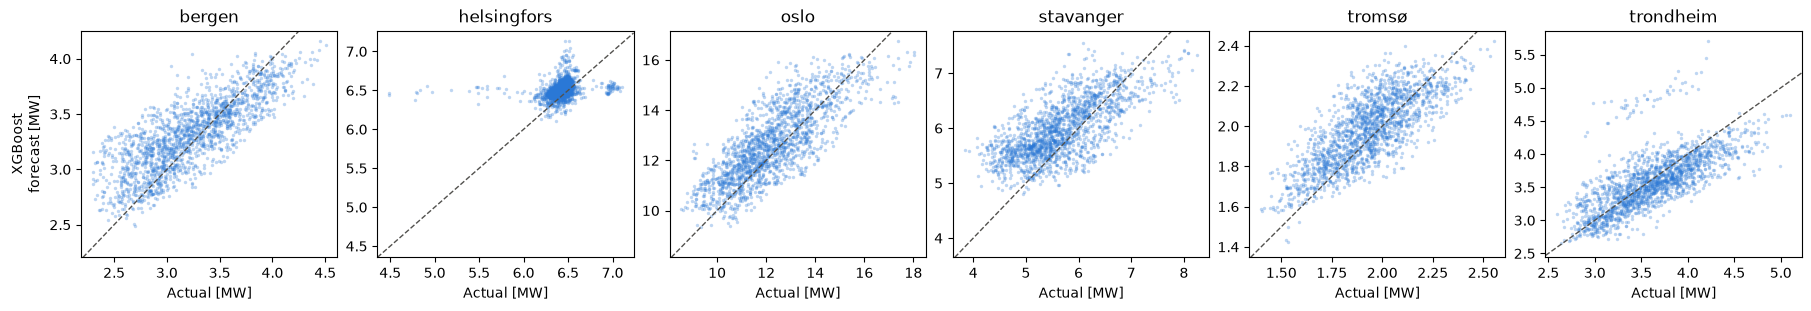

In [15]:
forecastValidator.plot_predicted_vs_actual_consumption(no_baseline=True)

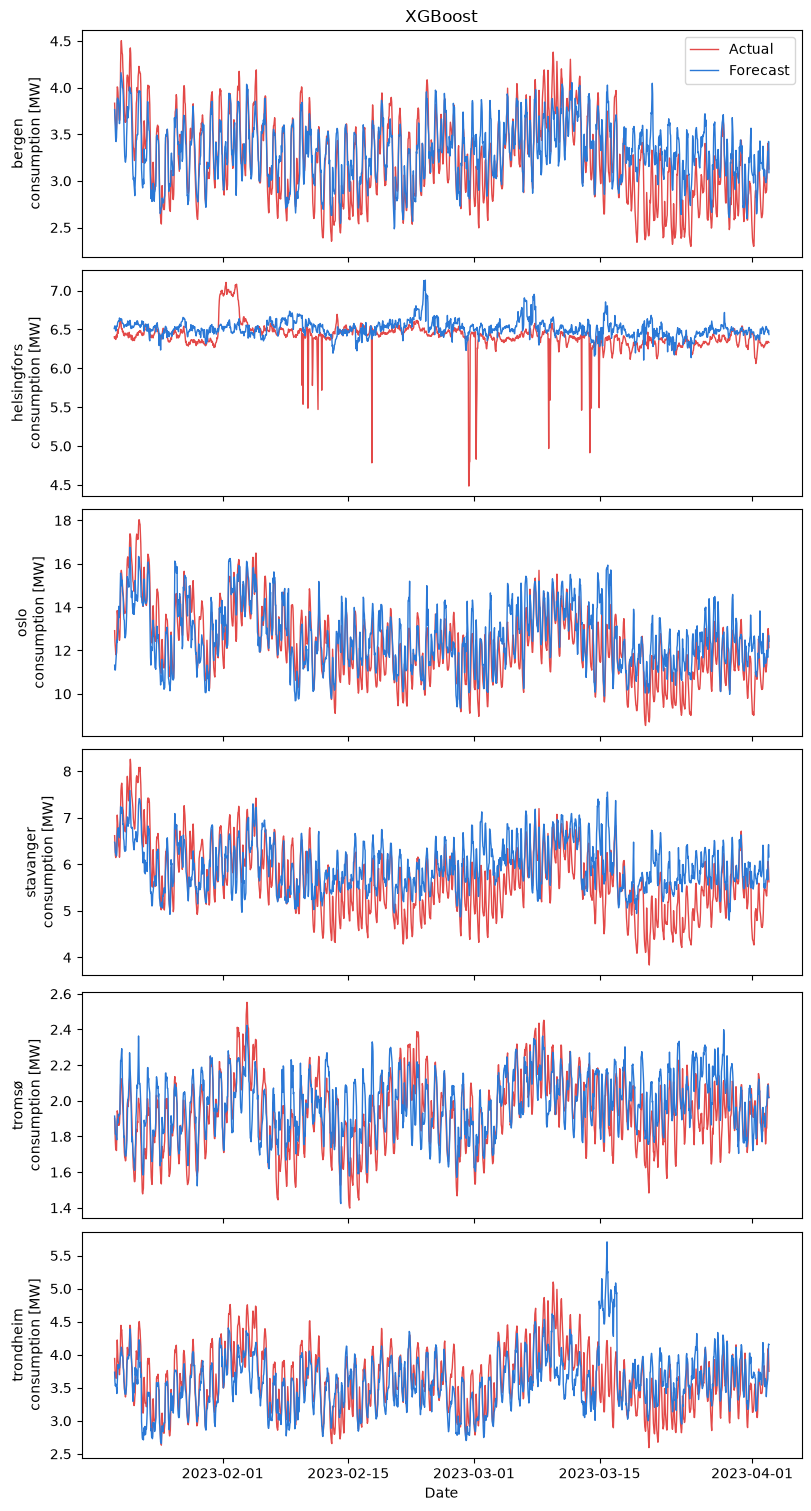

In [16]:
forecastValidator.plot_consumption_over_time(trainer.df.loc[y_test.index, "time"], no_baseline=True)